In [ ]:
# =========================================================================
# CELL 1: HARDWARE ACCELERATION SETUP & FAST RUNTIME DATA EXTRACTION
# =========================================================================
import os
import glob
import math
import zipfile
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import vgg16, VGG16_Weights
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Target Hardware Acceleration Engine Initialized: {device}")

# --- CONNECT GOOGLE DRIVE ---
try:
    from google.colab import drive
    print("Mounting Google Drive storage directory...")
    drive.mount('/content/drive')
except ImportError:
    print("Not running in Google Colab environment. Verifying local workspace paths...")

# --- FAST ARCHIVE UNPACKING ---
ZIP_PATH_ON_DRIVE = '/content/drive/MyDrive/Enlighten/lol_dataset.zip'
LOCAL_EXTRACT_TARGET = '/content/unzipped_lol/'

if os.path.exists(ZIP_PATH_ON_DRIVE):
    print(f"Archive dataset located at: '{ZIP_PATH_ON_DRIVE}'. Extracting components...")
    with zipfile.ZipFile(ZIP_PATH_ON_DRIVE, 'r') as zip_ref:
        zip_ref.extractall(LOCAL_EXTRACT_TARGET)
    print(f"Extraction complete! Extracted Local Destination Path: {LOCAL_EXTRACT_TARGET}")
    print("Contents verified inside local scratch memory:", os.listdir(LOCAL_EXTRACT_TARGET))
else:
    raise FileNotFoundError(f"Could not locate zip asset at '{ZIP_PATH_ON_DRIVE}'. Please verify path spelling.")

Target Hardware Acceleration Engine Initialized: cuda
Mounting Google Drive storage directory...
Mounted at /content/drive
Archive dataset located at: '/content/drive/MyDrive/Enlighten/lol_dataset.zip'. Extracting components...
Extraction complete! Extracted Local Destination Path: /content/unzipped_lol/
Contents verified inside local scratch memory: ['lol_dataset']


In [ ]:
# --- HIGH-SPEED PAIR CONTEXT DATA CONTAINER ---
class LocalRuntimeLOLDataset(Dataset):
    """ Loads paired low-light (Il) and ground-truth normal-light (In) image vectors. """
    def __init__(self, root_dir, split='our485', crop_size=256, is_train=True):
        self.is_train = is_train
        self.crop_size = crop_size

        target_folder = os.path.join(root_dir, 'lol_dataset', split)
        self.low_images = sorted(glob.glob(os.path.join(target_folder, 'low', '*.png')) +
                                 glob.glob(os.path.join(target_folder, 'low', '*.jpg')))
        self.high_images = sorted(glob.glob(os.path.join(target_folder, 'high', '*.png')) +
                                  glob.glob(os.path.join(target_folder, 'high', '*.jpg')))

        if len(self.low_images) == 0 or len(self.high_images) == 0:
            raise FileNotFoundError(f"Missing paired image matrix folder structures at: {target_folder}")

        assert len(self.low_images) == len(self.high_images), "Mismatched dataset low/high pairs count."
        self.transform = transforms.ToTensor()

    def __len__(self):
        return len(self.low_images)

    def __getitem__(self, idx):
        low_img = Image.open(self.low_images[idx]).convert('RGB')
        high_img = Image.open(self.high_images[idx]).convert('RGB')

        if self.is_train:
            # Synchronized random spatial cropping to improve generalization
            w, h = low_img.size
            th, tw = self.crop_size, self.crop_size
            if w > tw and h > th:
                i = torch.randint(0, h - th + 1, size=(1,)).item()
                j = torch.randint(0, w - tw + 1, size=(1,)).item()
                low_img = low_img.crop((j, i, j + tw, i + th))
                high_img = high_img.crop((j, i, j + tw, i + th))

            # Synchronized random horizontal flip data augmentation
            if torch.rand(1).item() > 0.5:
                low_img = low_img.transpose(Image.FLIP_LEFT_RIGHT)
                high_img = high_img.transpose(Image.FLIP_LEFT_RIGHT)

        return self.transform(low_img), self.transform(high_img)


# =========================================================================
# SEPARATED GENERATOR SUB-MODULES (AS SPECIFIED IN R2_IllumiGAN_Proposed.pdf)
# =========================================================================

# MODULE 1: Shared Shallow Encoder
class ShallowFeatureEncoder(nn.Module):
    def __init__(self, in_channels=3, out_channels=64):
        super(ShallowFeatureEncoder, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.leaky_relu = nn.LeakyReLU(0.2, inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)
        self.ln = nn.InstanceNorm2d(out_channels, affine=True)

    def forward(self, x):
        return self.ln(self.conv2(self.leaky_relu(self.conv1(x))))


# MODULE 2: Coarse Retinex Decomposition
class ResidualRetinexDecomposition(nn.Module):
    def __init__(self, channels=64):
        super(ResidualRetinexDecomposition, self).__init__()
        self.Dc = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(channels, 4, kernel_size=3, padding=1)
        )
        self.Dr = nn.Sequential(
            nn.Conv2d(channels + 4, channels, kernel_size=3, padding=1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(channels, 4, kernel_size=3, padding=1)
        )
        self.alpha_R = nn.Parameter(torch.FloatTensor([0.1]))
        self.alpha_L = nn.Parameter(torch.FloatTensor([0.1]))

    def forward(self, F0):
        coarse_out = self.Dc(F0)
        R0 = torch.sigmoid(coarse_out[:, 0:3, :, :])
        L0 = torch.sigmoid(coarse_out[:, 3:4, :, :])
        dr_input = torch.cat([F0, R0, L0], dim=1)
        residual_out = self.Dr(dr_input)
        delta_R = torch.tanh(residual_out[:, 0:3, :, :])
        delta_L = torch.tanh(residual_out[:, 3:4, :, :])
        R_hat = torch.clamp(R0 + self.alpha_R * delta_R, 0.0, 1.0)
        L_hat = torch.clamp(L0 + self.alpha_L * delta_L, 0.0, 1.0)
        return R_hat, L_hat


# MODULE 3: Reflectance Residual Branch
class GradientGuidedReflectanceRecovery(nn.Module):
    def __init__(self, channels=64):
        super(GradientGuidedReflectanceRecovery, self).__init__()
        self.conv_input = nn.Conv2d(3 + channels + 1, channels, kernel_size=3, padding=1)
        self.dense_block = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1)
        )
        self.attention_conv = nn.Conv2d(channels, 3, kernel_size=1)
        self.delta_conv = nn.Conv2d(channels, 3, kernel_size=3, padding=1)

    def forward(self, R_hat, F0, G_l):
        x = torch.cat([R_hat, F0, G_l], dim=1)
        F_R_g = self.dense_block(F.leaky_relu(self.conv_input(x), 0.2))
        A_g = torch.sigmoid(self.attention_conv(F_R_g))
        delta_Re = torch.tanh(self.delta_conv(F_R_g))
        return torch.clamp(R_hat + A_g * delta_Re, 0.0, 1.0)


# MODULE 4: Illumination Residual Branch
class IlluminationResidualBranch(nn.Module):
    def __init__(self, channels=64):
        super(IlluminationResidualBranch, self).__init__()
        self.local_path = nn.Sequential(
            nn.Conv2d(1 + channels, channels, kernel_size=3, padding=1),
            nn.LeakyReLU(0.2, inplace=True)
        )
        self.dilated1 = nn.Conv2d(1 + channels, channels, kernel_size=3, padding=1, dilation=1)
        self.dilated2 = nn.Conv2d(1 + channels, channels, kernel_size=3, padding=2, dilation=2)
        self.dilated4 = nn.Conv2d(1 + channels, channels, kernel_size=3, padding=4, dilation=4)
        self.dilated8 = nn.Conv2d(1 + channels, channels, kernel_size=3, padding=8, dilation=8)
        self.context_fusion = nn.Conv2d(channels * 4, channels, kernel_size=1)
        self.global_mlp = nn.Sequential(
            nn.Linear(channels, channels // 4), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(channels // 4, 1), nn.Sigmoid()
        )

    def forward(self, L_hat, F0):
        x = torch.cat([L_hat, F0], dim=1)
        F_local = self.local_path(x)
        F_context = self.context_fusion(torch.cat([
            F.leaky_relu(self.dilated1(x), 0.2), F.leaky_relu(self.dilated2(x), 0.2),
            F.leaky_relu(self.dilated4(x), 0.2), F.leaky_relu(self.dilated8(x), 0.2)
        ], dim=1))
        z_L = F.adaptive_avg_pool2d(F0, (1, 1)).view(F0.size(0), -1)
        gamma_map = self.global_mlp(z_L).view(F0.size(0), 1, 1, 1).expand(-1, -1, F0.size(2), F0.size(3))

        # This combination outputs the explicit 'L_enh path' tensor
        return torch.cat([F_local, F_context, gamma_map], dim=1)


# MODULE 5: Adaptive Illumination Enhancement
class AdaptiveIlluminationEnhancement(nn.Module):
    def __init__(self, channels=64):
        super(AdaptiveIlluminationEnhancement, self).__init__()
        self.attention_conv = nn.Conv2d(channels + channels + 1, 1, kernel_size=1)
        self.delta_conv = nn.Conv2d(channels + channels + 1, 1, kernel_size=3, padding=1)

    def forward(self, L_hat, F_L):
        M_L = torch.sigmoid(self.attention_conv(F_L))
        delta_Le = torch.tanh(self.delta_conv(F_L))
        return torch.clamp(L_hat + M_L * delta_Le, 0.0, 1.0)


# MODULE 6: Noise-Aware Residual Suppression
class NoiseAwareResidualSuppression(nn.Module):
    def __init__(self, channels=64):
        super(NoiseAwareResidualSuppression, self).__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3 + channels + 3 + 1, channels, kernel_size=3, padding=1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1), nn.LeakyReLU(0.2, inplace=True)
        )
        self.confidence_conv = nn.Conv2d(channels, 3, kernel_size=1)
        self.residual_conv = nn.Conv2d(channels, 3, kernel_size=3, padding=1)
        self.beta = nn.Parameter(torch.FloatTensor([0.2]))

    def forward(self, I_l, F0, R_e, L_e):
        x = torch.cat([I_l, F0, R_e, L_e], dim=1)
        F_N = self.network(x)
        C_N = torch.sigmoid(self.confidence_conv(F_N))
        N_r = torch.tanh(self.residual_conv(F_N))
        R_c = torch.clamp(R_e - self.beta * (C_N * N_r), 0.0, 1.0)
        return R_c, C_N


# MODULE 8: RGB Residual Refinement
class RGBResidualRefinement(nn.Module):
    def __init__(self, channels=64):
        super(RGBResidualRefinement, self).__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3 + 3 + channels, channels, kernel_size=3, padding=1), nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(channels, 3, kernel_size=3, padding=1), nn.Tanh()
        )

    def forward(self, I_l, I_r, F0):
        return self.net(torch.cat([I_l, I_r, F0], dim=1))


# --- FULLY DECOUPLED R2IllumiGAN GENERATOR MAPPING ---
class R2IllumiGANGenerator(nn.Module):
    def __init__(self):
        super(R2IllumiGANGenerator, self).__init__()

        self.E_s = ShallowFeatureEncoder()
        self.D_RR = ResidualRetinexDecomposition()
        self.E_R = GradientGuidedReflectanceRecovery()
        self.Illum_Res = IlluminationResidualBranch()
        self.Illum_Adapt = AdaptiveIlluminationEnhancement()
        self.N_S = NoiseAwareResidualSuppression()
        self.F_rec = RGBResidualRefinement()

    def forward(self, I_l):

        F0 = self.E_s(I_l)


        R_hat, L_hat = self.D_RR(F0)

        F_L = self.Illum_Res(L_hat, F0)



        L_e = self.Illum_Adapt(L_hat, F_L)


        G_l = self._compute_gradient_prior(I_l)

        R_e = self.E_R(R_hat, F0, G_l)


        R_c, C_N = self.N_S(I_l, F0, R_e, L_e)
        I_r = R_c * L_e

        I_n_hat = torch.clamp(
            I_r + self.F_rec(I_l, I_r, F0),
            0.0,
            1.0
        )
        return I_n_hat, L_e, R_c, C_N

    def _compute_gradient_prior(self, img):
        img_gray = 0.299 * img[:, 0:1, :, :] + 0.587 * img[:, 1:2, :, :] + 0.114 * img[:, 2:3, :, :]
        kernel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]], device=img.device, dtype=img.dtype).view(1, 1, 3, 3)
        kernel_y = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]], device=img.device, dtype=img.dtype).view(1, 1, 3, 3)
        grad_x = F.conv2d(img_gray, kernel_x, padding=1)
        grad_y = F.conv2d(img_gray, kernel_y, padding=1)
        return torch.sqrt(grad_x**2 + grad_y**2 + 1e-6)




# --- TRIPLE-DOMAIN ADV DISCRIMINATOR SYSTEMS ---
class TripleDomainDiscriminator(nn.Module):
    def __init__(self, channels=64):
        super(TripleDomainDiscriminator, self).__init__()
        def block(in_filters, out_filters, normalize=True):
            layers = [nn.Conv2d(in_filters, out_filters, 4, stride=2, padding=1)]
            if normalize: layers.append(nn.InstanceNorm2d(out_filters))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *block(3, channels, normalize=False),
            *block(channels, channels * 2),
            *block(channels * 2, channels * 4),
            *block(channels * 4, channels * 8),
            nn.Conv2d(channels * 8, 1, 4, padding=1)
        )
        self.conv_il = nn.Conv2d(1, channels, kernel_size=3, padding=1)
        self.conv_gr = nn.Conv2d(1, channels, kernel_size=3, padding=1)

        self.disc_il = nn.Sequential(*block(channels, channels * 2), nn.Conv2d(channels * 2, 1, 4, padding=1))
        self.disc_gr = nn.Sequential(*block(channels, channels * 2), nn.Conv2d(channels * 2, 1, 4, padding=1))

    def _compute_gradient_space(self, img):
        kx = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32).view(1, 1, 3, 3).to(img.device)
        ky = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=torch.float32).view(1, 1, 3, 3).to(img.device)
        gray = 0.299 * img[:, 0:1, :, :] + 0.587 * img[:, 1:2, :, :] + 0.114 * img[:, 2:3, :, :]
        return torch.sqrt(F.conv2d(gray, kx, padding=1)**2 + F.conv2d(gray, ky, padding=1)**2 + 1e-6)

    def forward(self, img_rgb, img_il):
        out_rgb = self.model(img_rgb)
        img_grad = self._compute_gradient_space(img_rgb)
        out_il = self.disc_il(self.conv_il(img_il))
        out_gr = self.disc_gr(self.conv_gr(img_grad))
        return out_rgb, out_il, out_gr

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:07<00:00, 71.5MB/s]



---> Launching Progressive 3-Stage Training Pipeline Engine...
Epoch [5/50] status update saved smoothly.
Epoch [10/50] status update saved smoothly.
Epoch [15/50] status update saved smoothly.
Epoch [20/50] status update saved smoothly.
Epoch [25/50] status update saved smoothly.
Epoch [30/50] status update saved smoothly.
Epoch [35/50] status update saved smoothly.
Epoch [40/50] status update saved smoothly.
Epoch [45/50] status update saved smoothly.
Epoch [50/50] status update saved smoothly.

Model weights saved to Drive storage! Plotting 6-Row Evaluation Sheet Matrix...


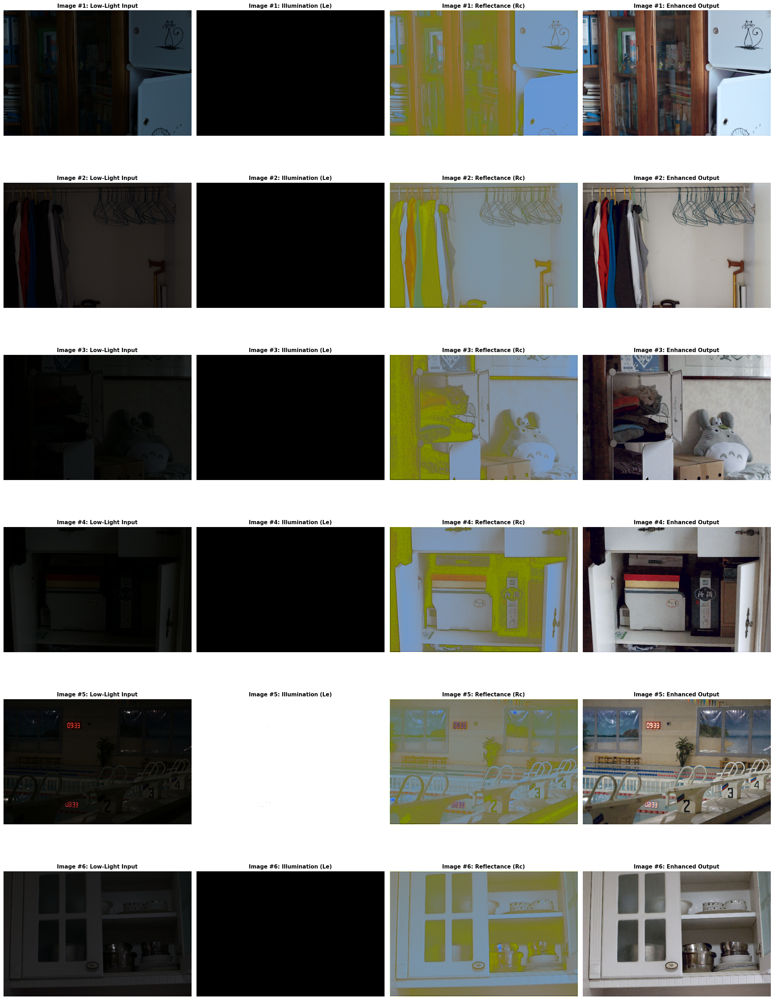

Multi-row physical validation sheets rendered successfully on screen above!


In [ ]:
# =========================================================================
# CELL 3: CRITERION CONSTRAINTS, STAGED TRAINING ENGINE, & 6-ROW PRESENTATION
# =========================================================================

# --- ALL 6 FORMULATED LOSS CRITERIONS ---
class ColorConstancyLoss(nn.Module):

    def forward(self, x):
        mean_rgb = torch.mean(x, dim=[2, 3], keepdim=True)
        mr, mg, mb = mean_rgb[:, 0, :, :], mean_rgb[:, 1, :, :], mean_rgb[:, 2, :, :]
        return torch.mean((mr - mg)**2) + torch.mean((mr - mb)**2) + torch.mean((mg - mb)**2)

class IlluminationSmoothnessLoss(nn.Module):

    def forward(self, L_e, R_c):
        gray_R = 0.299*R_c[:,0:1,:,:] + 0.587*R_c[:,1:2,:,:] + 0.114*R_c[:,2:3,:,:]
        def grad_x(img): return img[:, :, :, 1:] - img[:, :, :, :-1]
        def grad_y(img): return img[:, :, 1:, :] - img[:, :, :-1, :]
        weight_x = torch.exp(-2.0 * torch.abs(grad_x(gray_R)))
        weight_y = torch.exp(-2.0 * torch.abs(grad_y(gray_R)))
        return torch.mean(torch.abs(grad_x(L_e)) * weight_x) + torch.mean(torch.abs(grad_y(L_e)) * weight_y)

class GradientPreservationLoss(nn.Module):

    def forward(self, img1, img2):
        kx = torch.tensor([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=torch.float32).view(1, 1, 3, 3).to(img1.device)
        ky = torch.tensor([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=torch.float32).view(1, 1, 3, 3).to(img1.device)
        def get_g(img):
            g = 0.299*img[:,0:1,:,:] + 0.587*img[:,1:2,:,:] + 0.114*img[:,2:3,:,:]
            return torch.sqrt(F.conv2d(g, kx, padding=1)**2 + F.conv2d(g, ky, padding=1)**2 + 1e-6)
        return F.l1_loss(get_g(img1), get_g(img2))

class NoiseSuppressionLoss(nn.Module):

    def forward(self, C_N, I_l, I_n_hat):
        return F.l1_loss(C_N * I_l, C_N * (I_l - I_n_hat))

class PerceptualLoss(nn.Module):

    def __init__(self):
        super(PerceptualLoss, self).__init__()
        vgg = vgg16(weights=VGG16_Weights.DEFAULT).features
        self.slice = nn.Sequential(*[vgg[i] for i in range(16)]).eval()
        for param in self.slice.parameters(): param.requires_grad = False
    def forward(self, target, reference): return F.l1_loss(self.slice(target), self.slice(reference))

class SSIMLoss(nn.Module):

    def __init__(self, window_size=11):
        super(SSIMLoss, self).__init__()
        self.window_size = window_size
        self.register_buffer('window', self._create_window(window_size))
    def _gaussian(self, size, sigma):
        gauss = torch.Tensor([math.exp(-(x - size//2)**2 / float(2*sigma**2)) for x in range(size)])
        return gauss / gauss.sum()
    def _create_window(self, size, channel=3):
        _1D_window = self._gaussian(size, 1.5).unsqueeze(1)
        return _1D_window.mm(_1D_window.t()).float().unsqueeze(0).unsqueeze(0).expand(channel, 1, size, size).contiguous()
    def forward(self, img1, img2):
        mu1 = F.conv2d(img1, self.window, padding=self.window_size//2, groups=3)
        mu2 = F.conv2d(img2, self.window, padding=self.window_size//2, groups=3)
        sigma1_sq = F.conv2d(img1*img1, self.window, padding=self.window_size//2, groups=3) - mu1.pow(2)
        sigma2_sq = F.conv2d(img2*img2, self.window, padding=self.window_size//2, groups=3) - mu2.pow(2)
        sigma12 = F.conv2d(img1*img2, self.window, padding=self.window_size//2, groups=3) - (mu1 * mu2)
        c1, c2 = 0.01**2, 0.03**2
        return 1.0 - (((2*(mu1*mu2) + c1)*(2*sigma12 + c2)) / ((mu1.pow(2) + mu2.pow(2) + c1)*(sigma1_sq + sigma2_sq + c2))).mean()

# --- 3-STAGE OPTIMIZATION SCHEDULER ENGINE ---
def run_progressive_training(dataset_root, batch_size=4, stages_epochs=(15, 40, 50)):
    train_set = LocalRuntimeLOLDataset(root_dir=dataset_root, split='our485', is_train=True)
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=2, drop_last=True)
    val_set = LocalRuntimeLOLDataset(root_dir=dataset_root, split='eval15', is_train=False)

    generator = R2IllumiGANGenerator().to(device)
    discriminator = TripleDomainDiscriminator().to(device)

    # Adam parameters initialization
    optimizer_G = torch.optim.Adam(generator.parameters(), lr=2e-4, betas=(0.5, 0.999))
    optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=2e-4, betas=(0.5, 0.999))

    loss_ssim = SSIMLoss().to(device)
    loss_vgg = PerceptualLoss().to(device)
    loss_color = ColorConstancyLoss().to(device)
    loss_smooth = IlluminationSmoothnessLoss().to(device)
    loss_grad = GradientPreservationLoss().to(device)
    loss_noise = NoiseSuppressionLoss().to(device)

    stg1, stg2, stg3 = stages_epochs
    total_epochs = stg1 + stg2 + stg3

    print("\n---> Launching Progressive 3-Stage Training Pipeline Engine...")
    for epoch in range(1, total_epochs + 1):
        generator.train()
        for idx, (I_l, I_n) in enumerate(train_loader):
            I_l, I_n = I_l.to(device), I_n.to(device)
            I_n_hat, L_e, R_c, C_N = generator(I_l)

            # STAGE I: Retinex Decomposition Pretraining
            if epoch <= stg1:
                optimizer_G.zero_grad()
                L_G_stg1 = F.l1_loss(I_n_hat, I_n) + 0.5 * loss_smooth(L_e, R_c)
                L_G_stg1.backward()
                optimizer_G.step()

            # STAGE II: Residual Joint Context Enhancement
            elif epoch <= stg1 + stg2:
                optimizer_G.zero_grad()
                L_G_stg2 = (F.l1_loss(I_n_hat, I_n) + loss_ssim(I_n_hat, I_n) +
                            loss_vgg(I_n_hat, I_n) + 0.5 * loss_color(I_n_hat) +
                            0.1 * loss_smooth(L_e, R_c) + loss_grad(I_n_hat, I_n) +
                            loss_noise(C_N, I_l, I_n_hat))
                L_G_stg2.backward()
                optimizer_G.step()

            # STAGE III: Least-Squares Triple Domain Fine-Tuning
            else:
                # Alternate Step A: Update Triple-Domain Discriminators
                optimizer_D.zero_grad()
                r_rgb, r_il, r_gr = discriminator(I_n, L_e.detach())
                loss_D_real = 0.5 * (torch.mean((r_rgb - 1)**2) + torch.mean((r_il - 1)**2) + torch.mean((r_gr - 1)**2))
                f_rgb, f_il, f_gr = discriminator(I_n_hat.detach(), L_e.detach())
                loss_D_fake = 0.5 * (torch.mean(f_rgb**2) + torch.mean(f_il**2) + torch.mean(f_gr**2))
                (loss_D_real + loss_D_fake).backward()
                optimizer_D.step()

                # Alternate Step B: Update Generator via COMPLETE Multi-Term Objective Map
                optimizer_G.zero_grad()
                g_rgb, g_il, g_gr = discriminator(I_n_hat, L_e)
                loss_adv = 0.5 * (torch.mean((g_rgb - 1)**2) + torch.mean((g_il - 1)**2) + torch.mean((g_gr - 1)**2))

                L_G_complete = (F.l1_loss(I_n_hat, I_n) + loss_ssim(I_n_hat, I_n) +
                                loss_vgg(I_n_hat, I_n) + 0.5 * loss_color(I_n_hat) +
                                0.1 * loss_smooth(L_e, R_c) + loss_grad(I_n_hat, I_n) +
                                loss_noise(C_N, I_l, I_n_hat) + 0.1 * loss_adv)
                L_G_complete.backward()
                optimizer_G.step()

        if epoch % 5 == 0 or epoch == total_epochs:
            print(f"Epoch [{epoch}/{total_epochs}] status update saved smoothly.")

    # Save stable parameter states permanently back to Drive [cite: 337]
   # Change this:
# torch.save(generator.state_dict(), "/content/drive/MyDrive/Enlighten/r2_illumigan_generator_strict.pth")

# To this:
    torch.save(generator.state_dict(), "/content/drive/MyDrive/Enlighten/r2_illumigan_generator_strict.pth")
    print("\nModel weights saved to Drive storage! Plotting 6-Row Evaluation Sheet Matrix...")

    # -----------------------------------------------------------------
    # NATIVE MULTI-ROW 6-IMAGE VALIDATION VISUALIZER HUB
    # -----------------------------------------------------------------
    generator.eval()

    # Fixed index targets selected across the eval15 validation folder directory tree
    expanded_indices = [0, 2, 5, 8, 11, 14]

    fig, axes = plt.subplots(6, 4, figsize=(22, 30)) # Expanded canvas to support 6 full rows
    for idx_row, test_idx in enumerate(expanded_indices):
        test_low, _ = val_set[test_idx]
        input_tensor = test_low.unsqueeze(0).to(device)

        with torch.no_grad():
            enhanced_tensor, illum_map, ref_map, _ = generator(input_tensor) # Single forward pass [cite: 338]

        # Convert back to standard CPU Numpy viewable image channel forms
        raw_visual = test_low.permute(1, 2, 0).cpu().numpy()
        illum_visual = illum_map.squeeze(0).squeeze(0).cpu().numpy()
        ref_visual = ref_map.squeeze(0).permute(1, 2, 0).cpu().numpy()
        enhanced_visual = enhanced_tensor.squeeze(0).permute(1, 2, 0).cpu().numpy()

        # Render rows sequentially
        axes[idx_row, 0].imshow(np.clip(raw_visual, 0.0, 1.0))
        axes[idx_row, 0].set_title(f"Image #{idx_row+1}: Low-Light Input", fontsize=11, fontweight='bold')
        axes[idx_row, 0].axis('off')

        axes[idx_row, 1].imshow(np.clip(illum_visual, 0.0, 1.0), cmap='gray')
        axes[idx_row, 1].set_title(f"Image #{idx_row+1}: Illumination (Le)", fontsize=11, fontweight='bold')
        axes[idx_row, 1].axis('off')

        axes[idx_row, 2].imshow(np.clip(ref_visual, 0.0, 1.0))
        axes[idx_row, 2].set_title(f"Image #{idx_row+1}: Reflectance (Rc)", fontsize=11, fontweight='bold')
        axes[idx_row, 2].axis('off')

        axes[idx_row, 3].imshow(np.clip(enhanced_visual, 0.0, 1.0))
        axes[idx_row, 3].set_title(f"Image #{idx_row+1}: Enhanced Output", fontsize=11, fontweight='bold')
        axes[idx_row, 3].axis('off')

    plt.tight_layout()
    plt.savefig("/content/drive/MyDrive/Enlighten/r2_illumigan_baseline_output.png", dpi=300)
    plt.show()
    print("Multi-row physical validation sheets rendered successfully on screen above!")

# Trigger execution engine matching research guidelines
run_progressive_training(dataset_root='/content/unzipped_lol/', batch_size=4, stages_epochs=(10, 20, 20))

In [ ]:
import os

for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if file.endswith('.pth'):
            print(os.path.join(root, file))

/content/drive/MyDrive/Enlighten/r2_illumigan_generator.pth
/content/drive/MyDrive/Enlighten/r2_illumigan_generator_strict.pth
/content/drive/MyDrive/Enlighten/ablation_skip_module1.pth
/content/drive/MyDrive/Enlighten/ablation_skip_module2.pth
/content/drive/MyDrive/Enlighten/ablation_skip_module3.pth
/content/drive/MyDrive/Enlighten/ablation_skip_module4.pth
/content/drive/MyDrive/Enlighten/ablation_skip_module6.pth
/content/drive/MyDrive/Enlighten/ablation_skip_module8.pth


In [ ]:
generator = R2IllumiGANGenerator().to(device)

generator.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/Enlighten/r2_illumigan_generator_strict.pth",
        map_location=device
    )
)

generator.eval()

print("Baseline Model loaded successfully")

Baseline Model loaded successfully


In [ ]:
import time
import torch

# Create the test dataset
val_set = LocalRuntimeLOLDataset(
    root_dir='/content/unzipped_lol/',
    split='eval15',
    is_train=False
)

times = []

print("Inference Time for Each LOL Test Image\n")

for i in range(len(val_set)):

    low_img, _ = val_set[i]
    input_tensor = low_img.unsqueeze(0).to(device)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    with torch.no_grad():
        enhanced, illum, reflectance, _ = generator(input_tensor)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end = time.perf_counter()

    t = (end - start) * 1000
    times.append(t)

    print(f"Image {i+1:02d}: {t:.3f} ms")

print("\n==============================")
print(f"Average Time : {sum(times)/len(times):.3f} ms")
print(f"Minimum Time : {min(times):.3f} ms")
print(f"Maximum Time : {max(times):.3f} ms")

Inference Time for Each LOL Test Image

Image 01: 121.727 ms
Image 02: 117.331 ms
Image 03: 94.472 ms
Image 04: 94.251 ms
Image 05: 95.858 ms
Image 06: 93.683 ms
Image 07: 95.193 ms
Image 08: 93.009 ms
Image 09: 95.190 ms
Image 10: 88.023 ms
Image 11: 90.920 ms
Image 12: 89.981 ms
Image 13: 102.282 ms
Image 14: 98.378 ms
Image 15: 87.209 ms

Average Time : 97.167 ms
Minimum Time : 87.209 ms
Maximum Time : 121.727 ms


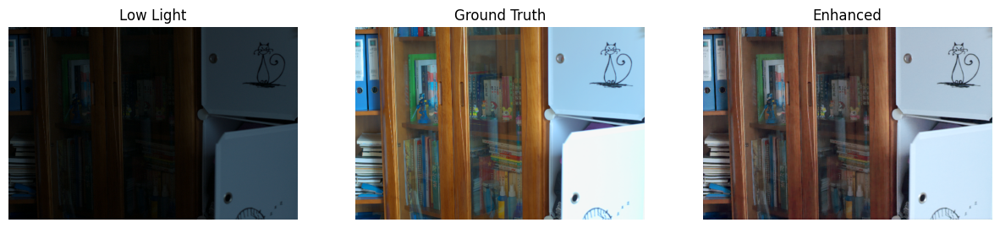

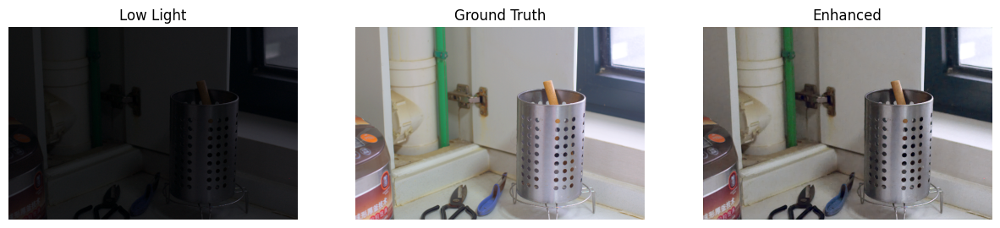

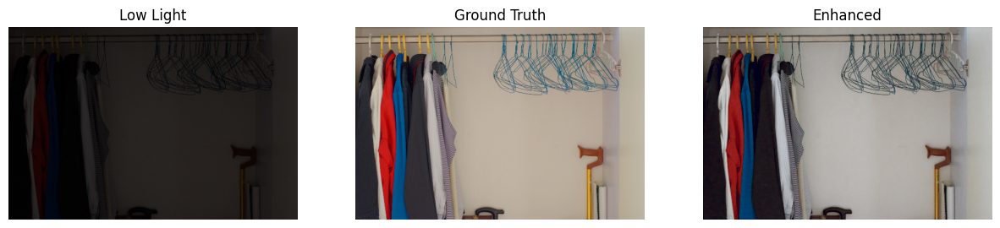

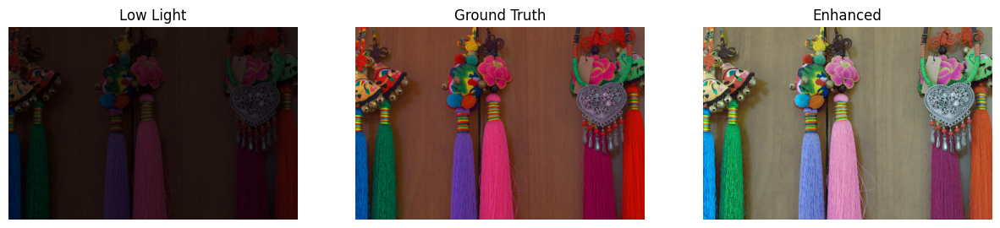

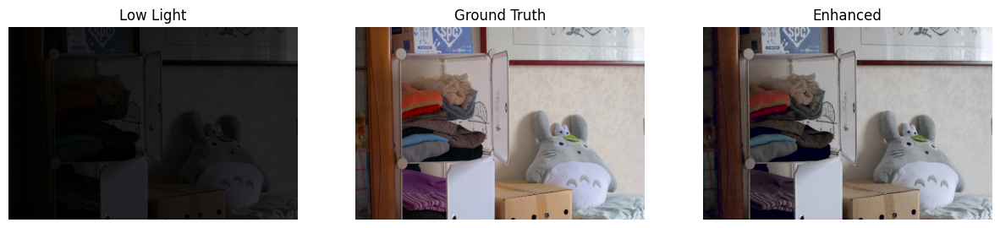

...

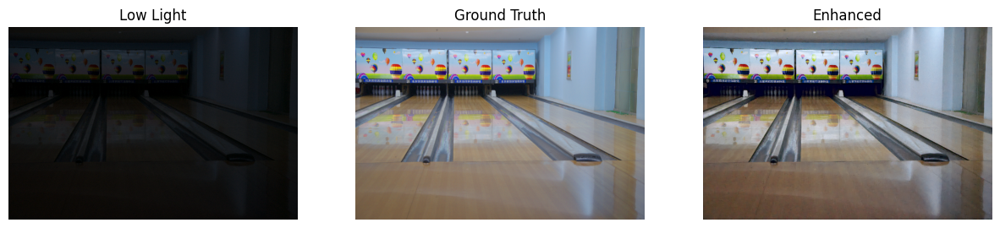

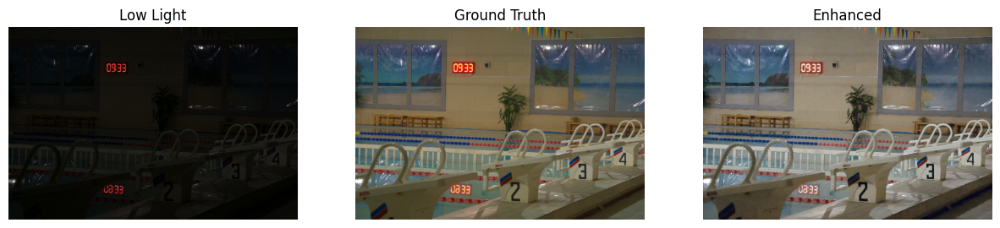

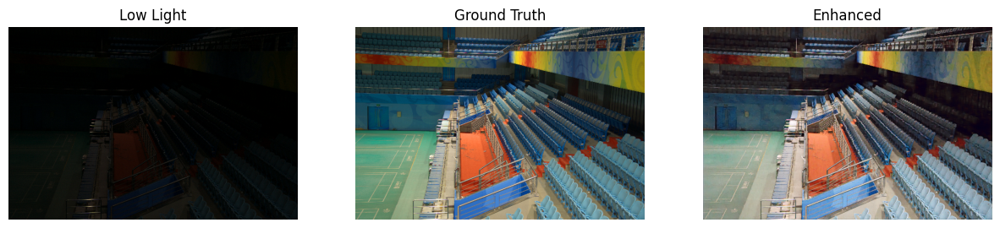

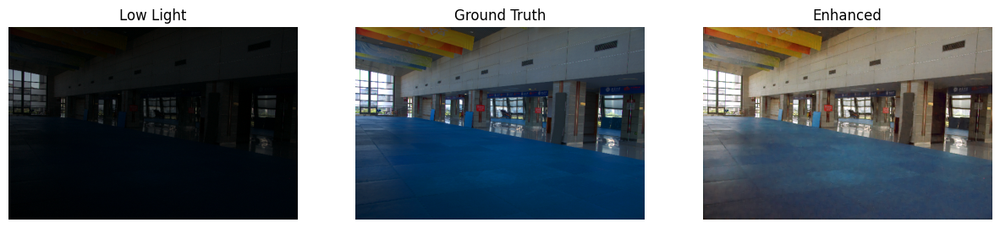

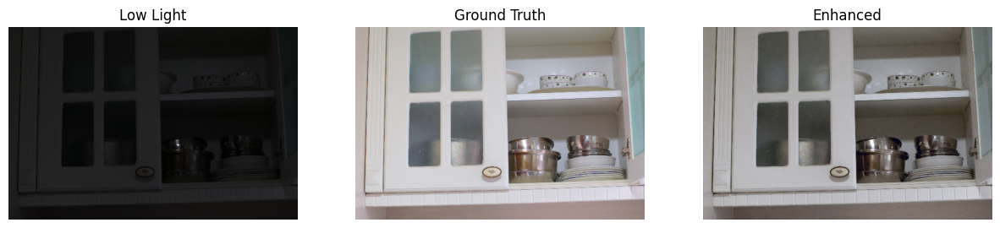

In [ ]:
val_set = LocalRuntimeLOLDataset(
    root_dir='/content/unzipped_lol/',
    split='eval15',
    is_train=False
)

for i in range(15):  # test first 15 images

    low_img, high_img = val_set[i]

    input_tensor = low_img.unsqueeze(0).to(device)

    with torch.no_grad():
        enhanced, illum, reflectance, _ = generator(input_tensor)

    plt.figure(figsize=(15,5))

    plt.subplot(1,3,1)
    plt.imshow(low_img.permute(1,2,0))
    plt.title("Low Light")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(high_img.permute(1,2,0))
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(enhanced.squeeze(0).permute(1,2,0).cpu())
    plt.title("Enhanced")
    plt.axis("off")

    plt.show()

In [ ]:
import os
from torchvision import transforms

save_folder = "/content/Baseline_Enhanced"
os.makedirs(save_folder, exist_ok=True)

for i in range(len(val_set)):

    low_img, _ = val_set[i]

    input_tensor = low_img.unsqueeze(0).to(device)

    with torch.no_grad():
        enhanced, _, _, _ = generator(input_tensor)

    transforms.ToPILImage()(enhanced.squeeze(0).cpu()).save(
        os.path.join(save_folder, f"LOL_{i+1:03d}.png")
    )

print("Saved all enhanced images.")

Saved all enhanced images.


In [ ]:
!zip -r Baseline_Enhanced.zip /content/Baseline_Enhanced

  adding: content/Baseline_Enhanced/ (stored 0%)
  adding: content/Baseline_Enhanced/LOL_007.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_008.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_002.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_011.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_013.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_010.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_012.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_005.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_009.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_001.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_015.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_014.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_004.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_003.png (deflated 0%)
  adding: content/Baseline_Enhanced/LOL_006.png (deflated 0%)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!ls /content

drive	      LOL_Enhanced.zip	U45-20260611T165910Z-3-001.zip
LOL_Enhanced  sample_data	unzipped_lol


In [ ]:
import zipfile

zip_path = "/content/U45-20260611T165910Z-3-001.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/U45")

print("U45 extracted successfully")

U45 extracted successfully


In [ ]:
import os
from PIL import Image
from torchvision import transforms

u45_input = "/content/U45/U45"
u45_output = "/content/U45_Enhanced"

os.makedirs(u45_output, exist_ok=True)

image_files = sorted([
    f for f in os.listdir(u45_input)
    if f.endswith((".png", ".jpg", ".jpeg"))
])

for img_name in image_files:

    img_path = os.path.join(u45_input, img_name)

    img = Image.open(img_path).convert("RGB")

    input_tensor = transforms.ToTensor()(img).unsqueeze(0).to(device)

    with torch.no_grad():
        enhanced, _, _, _ = generator(input_tensor)

    enhanced_img = enhanced.squeeze(0).cpu()

    save_path = os.path.join(u45_output, img_name)

    transforms.ToPILImage()(enhanced_img).save(save_path)

print("U45 enhancement completed.")

U45 enhancement completed.


In [ ]:
!zip -r U45_Enhanced.zip /content/U45_Enhanced

  adding: content/U45_Enhanced/ (stored 0%)
  adding: content/U45_Enhanced/16.png (deflated 0%)
  adding: content/U45_Enhanced/4.png (deflated 0%)
  adding: content/U45_Enhanced/3.png (deflated 0%)
  adding: content/U45_Enhanced/17.png (deflated 0%)
  adding: content/U45_Enhanced/2.png (deflated 0%)
  adding: content/U45_Enhanced/7.png (deflated 0%)
  adding: content/U45_Enhanced/1.png (deflated 0%)
  adding: content/U45_Enhanced/15.png (deflated 0%)
  adding: content/U45_Enhanced/12.png (deflated 0%)
  adding: content/U45_Enhanced/14.png (deflated 0%)
  adding: content/U45_Enhanced/13.png (deflated 0%)
  adding: content/U45_Enhanced/9.png (deflated 0%)
  adding: content/U45_Enhanced/6.png (deflated 0%)
  adding: content/U45_Enhanced/8.png (deflated 0%)
  adding: content/U45_Enhanced/5.png (deflated 0%)
  adding: content/U45_Enhanced/11.png (deflated 0%)
  adding: content/U45_Enhanced/10.png (deflated 0%)
  adding: content/U45_Enhanced/18.png (deflated 0%)


In [ ]:
from google.colab import files
files.download("U45_Enhanced.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile

zip_path = "/content/NPE-20260611T172343Z-3-001.zip"
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/NPE")

print("NPE extracted successfully")

NPE extracted successfully


In [ ]:
import os
from PIL import Image
from torchvision import transforms

npe_input = "/content/NPE/NPE"      # adjust if structure differs
npe_output = "/content/NPE_Enhanced"

os.makedirs(npe_output, exist_ok=True)

image_files = sorted([
    f for f in os.listdir(npe_input)
    if f.endswith((".png", ".jpg", ".jpeg"))
])

for img_name in image_files:

    img = Image.open(os.path.join(npe_input, img_name)).convert("RGB")

    input_tensor = transforms.ToTensor()(img).unsqueeze(0).to(device)

    with torch.no_grad():
        enhanced, _, _, _ = generator(input_tensor)

    transforms.ToPILImage()(
        enhanced.squeeze(0).cpu()
    ).save(os.path.join(npe_output, img_name))

print("NPE enhancement completed.")

NPE enhancement completed.


In [ ]:
!zip -r NPE_Enhanced.zip /content/NPE_Enhanced

  adding: content/NPE_Enhanced/ (stored 0%)
  adding: content/NPE_Enhanced/road.png (deflated 0%)
  adding: content/NPE_Enhanced/birds.png (deflated 0%)
  adding: content/NPE_Enhanced/skyscraper.png (deflated 0%)
  adding: content/NPE_Enhanced/sculpture.png (deflated 0%)
  adding: content/NPE_Enhanced/night fall.png (deflated 0%)
  adding: content/NPE_Enhanced/harbor.png (deflated 0%)
  adding: content/NPE_Enhanced/rail.png (deflated 0%)
  adding: content/NPE_Enhanced/Parking.png (deflated 0%)


In [ ]:
from google.colab import files
files.download("NPE_Enhanced.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import zipfile

zip_files = {

    "/content/MEF-20260611T173757Z-3-001.zip": "/content/MEF",
    "/content/DCIM-20260611T173806Z-3-001.zip": "/content/DCIM"
}

for zip_path, extract_path in zip_files.items():

    try:
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_path)

        print(f"✓ Extracted: {zip_path}")

    except Exception as e:
        print(f"✗ Failed: {zip_path}")
        print(e)

print("All extraction completed.")

✓ Extracted: /content/MEF-20260611T173757Z-3-001.zip
✓ Extracted: /content/DCIM-20260611T173806Z-3-001.zip
All extraction completed.


In [ ]:
import os
from PIL import Image
from torchvision import transforms

datasets = {

    "MEF": {
        "input": "/content/MEF/MEF",
        "output": "/content/MEF_Enhanced"
    },
    "DCIM": {
        "input": "/content/DCIM/DCIM",
        "output": "/content/DCIM_Enhanced"
    }
}

for dataset_name, paths in datasets.items():

    INPUT_FOLDER = paths["input"]
    OUTPUT_FOLDER = paths["output"]

    os.makedirs(OUTPUT_FOLDER, exist_ok=True)

    print(f"\nProcessing {dataset_name}...")

    for img_name in sorted(os.listdir(INPUT_FOLDER)):

        if not img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
            continue

        img = Image.open(
            os.path.join(INPUT_FOLDER, img_name)
        ).convert("RGB")

        input_tensor = transforms.ToTensor()(img).unsqueeze(0).to(device)

        with torch.no_grad():
            enhanced, _, _, _ = generator(input_tensor)

        transforms.ToPILImage()(
            enhanced.squeeze(0).cpu()
        ).save(
            os.path.join(OUTPUT_FOLDER, img_name)
        )

    print(f"{dataset_name} completed.")

print("\nAll datasets processed successfully.")


Processing MEF...
MEF completed.

Processing DCIM...
DCIM completed.

All datasets processed successfully.


In [ ]:

!zip -r MEF_Enhanced.zip /content/MEF_Enhanced
!zip -r DCIM_Enhanced.zip /content/DCIM_Enhanced

updating: content/MEF_Enhanced/ (stored 0%)
updating: content/MEF_Enhanced/BelgiumHouse.png (deflated 0%)
updating: content/MEF_Enhanced/Memorial.png (deflated 0%)
updating: content/MEF_Enhanced/House.png (deflated 0%)
updating: content/MEF_Enhanced/Kluki.png (deflated 0%)
updating: content/MEF_Enhanced/Cadik.png (deflated 0%)
updating: content/MEF_Enhanced/LightHouse.png (deflated 0%)
updating: content/MEF_Enhanced/Venice.png (deflated 0%)
updating: content/MEF_Enhanced/Candle.png (deflated 0%)
updating: content/MEF_Enhanced/Tower.png (deflated 0%)
updating: content/MEF_Enhanced/Office.png (deflated 0%)
updating: content/MEF_Enhanced/Farmhouse.png (deflated 0%)
updating: content/MEF_Enhanced/ChineseGarden.png (deflated 0%)
updating: content/MEF_Enhanced/Cave.png (deflated 0%)
updating: content/MEF_Enhanced/Landscape.png (deflated 0%)
updating: content/MEF_Enhanced/Lamp.png (deflated 0%)
updating: content/MEF_Enhanced/Madison.png (deflated 0%)
updating: content/MEF_Enhanced/Balloons.pn

In [ ]:
from google.colab import files


files.download("MEF_Enhanced.zip")
files.download("DCIM_Enhanced.zip")
print("completed")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

completed


In [ ]:
import zipfile

zip_path = "/content/LIME-20260611T173802Z-3-001.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/LIME")

print("LIME extracted successfully")

LIME extracted successfully


In [ ]:
import os
from PIL import Image
from torchvision import transforms

INPUT_FOLDER = "/content/LIME/LIME"      # LIME images
OUTPUT_FOLDER = "/content/LIME_Enhanced" # Enhanced outputs

os.makedirs(OUTPUT_FOLDER, exist_ok=True)

for img_name in sorted(os.listdir(INPUT_FOLDER)):

    if not img_name.lower().endswith(('.png', '.jpg', '.jpeg','.bmp')):
        continue

    img = Image.open(
        os.path.join(INPUT_FOLDER, img_name)
    ).convert("RGB")

    input_tensor = transforms.ToTensor()(img).unsqueeze(0).to(device)

    with torch.no_grad():
        enhanced, _, _, _ = generator(input_tensor)

    transforms.ToPILImage()(
        enhanced.squeeze(0).cpu()
    ).save(
        os.path.join(OUTPUT_FOLDER, img_name)
    )

print("LIME enhancement completed.")

LIME enhancement completed.


In [ ]:
!zip -r LIME_Enhanced.zip /content/LIME_Enhanced


updating: content/LIME_Enhanced/ (stored 0%)
  adding: content/LIME_Enhanced/4.bmp (deflated 33%)
  adding: content/LIME_Enhanced/8.bmp (deflated 20%)
  adding: content/LIME_Enhanced/6.bmp (deflated 9%)
  adding: content/LIME_Enhanced/7.bmp (deflated 43%)
  adding: content/LIME_Enhanced/2.bmp (deflated 29%)
  adding: content/LIME_Enhanced/3.bmp (deflated 11%)
  adding: content/LIME_Enhanced/1.bmp (deflated 26%)
  adding: content/LIME_Enhanced/5.bmp (deflated 16%)
  adding: content/LIME_Enhanced/9.bmp (deflated 49%)
  adding: content/LIME_Enhanced/10.bmp (deflated 12%)


In [ ]:
from google.colab import files


files.download("LIME_Enhanced.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>